# 01 — Exploratory Data Analysis
**Dataset:** CDC Diabetes Health Indicators (UCI #891, BRFSS 2015)

EDA here is **descriptive only**: we look at the full dataset to understand it, but we make **no modelling
decisions that use test labels** (no feature selection, no threshold choice). Those happen after the split.

Every figure is saved to `figures/` so it can go straight into the report.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, str(Path.cwd().parent / "src"))
from config import FIGURES_DIR, RESULTS_DIR, TARGET
from data_loader import load_dataset

FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# One colour per class, used in every plot, so readers learn it once.
COLOR_NO_DIABETES = "#2a78d6"
COLOR_DIABETES = "#eb6834"
TEXT_MUTED = "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10})

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

df = load_dataset()
df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


## 1. Data quality check
Missing values, duplicates and value ranges. This table goes in the report's *Dataset* section.

In [2]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
quality.to_csv(RESULTS_DIR / "eda_data_quality.csv")

n_dup = df.duplicated().sum()
print(f"Rows: {len(df):,} | Features: {df.shape[1] - 1} | Missing cells: {df.isna().sum().sum()}")
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / len(df):.1%})")
quality

Rows: 253,680 | Features: 21 | Missing cells: 0
Exact duplicate rows: 24,206 (9.5%)


,dtype,missing,unique_values,min,max
HighBP,int64,0,2,0,1
HighChol,int64,0,2,0,1
CholCheck,int64,0,2,0,1
BMI,int64,0,84,12,98
Smoker,int64,0,2,0,1
Stroke,int64,0,2,0,1
HeartDiseaseorAttack,int64,0,2,0,1
PhysActivity,int64,0,2,0,1
Fruits,int64,0,2,0,1
Veggies,int64,0,2,0,1


**Why duplicates matter:** most features are binary or bucketed, so two different people can give identical answers.
But if identical rows land in both train and test, the model is partly tested on rows it has already seen. That inflates scores.
→ In preprocessing we **drop exact duplicates before splitting**. Below we check whether duplicates are spread evenly across the two classes.

In [3]:
dup_rate_by_class = df[df.duplicated(keep=False)][TARGET].value_counts(normalize=True)
print("Class mix among duplicated rows:\n", dup_rate_by_class.round(3))
print("\nClass mix in full data:\n", df[TARGET].value_counts(normalize=True).round(3))

Class mix among duplicated rows:
 Diabetes_binary
0    0.987
1    0.013
Name: proportion, dtype: float64

Class mix in full data:
 Diabetes_binary
0    0.861
1    0.139
Name: proportion, dtype: float64


## 2. Target class distribution (imbalance)

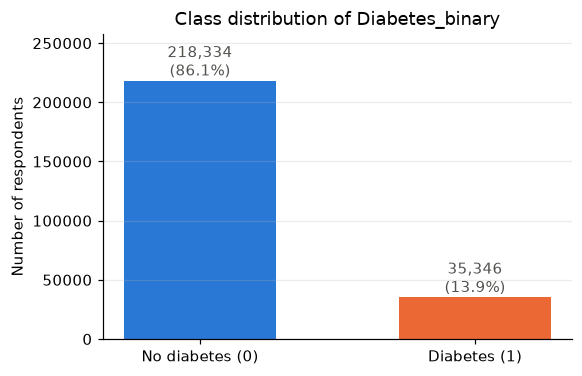

A model that always predicts 'no diabetes' would already score 86.1% accuracy.


In [4]:
counts = df[TARGET].value_counts().sort_index()
labels = ["No diabetes (0)", "Diabetes (1)"]

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(labels, counts.values, color=[COLOR_NO_DIABETES, COLOR_DIABETES], width=0.55)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({n / len(df):.1%})",
            ha="center", va="bottom", color=TEXT_MUTED)
ax.set_ylabel("Number of respondents")
ax.set_title("Class distribution of Diabetes_binary")
ax.set_ylim(0, counts.max() * 1.18)
ax.grid(axis="x", visible=False)
save(fig, "eda_01_class_distribution")
plt.show()

majority_share = counts.max() / len(df)
print(f"A model that always predicts 'no diabetes' would already score {majority_share:.1%} accuracy.")

## 3. Diabetes rate by key indicators
Instead of raw counts we plot the **percentage of people with diabetes** in each group. That is easier to read when groups differ in size.
The dashed line is the overall rate (13.9%).

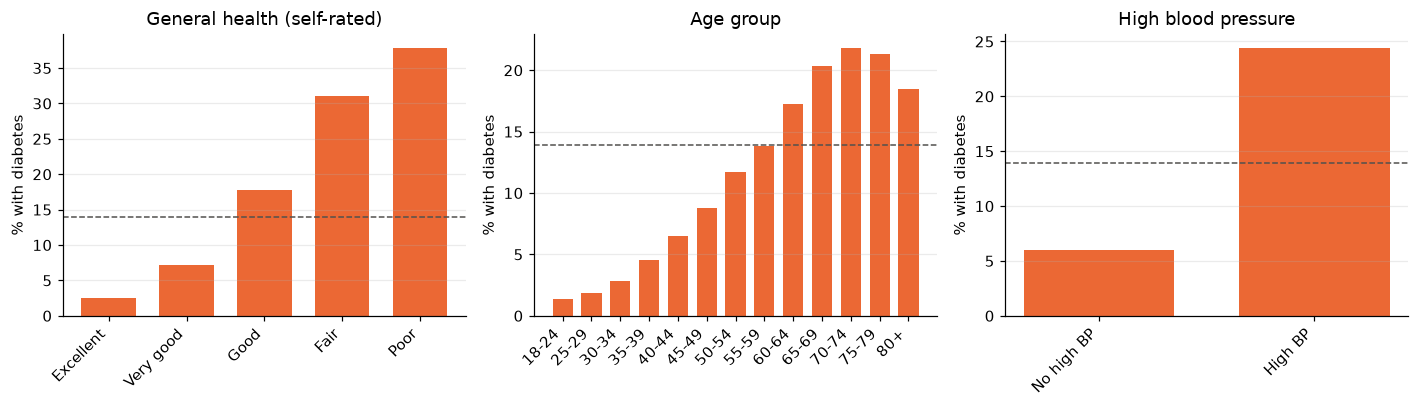

In [5]:
overall_rate = df[TARGET].mean()

def plot_rate(ax, column, tick_labels=None, title=None):
    rate = df.groupby(column)[TARGET].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=COLOR_DIABETES, width=0.7)
    ax.axhline(overall_rate * 100, ls="--", lw=1, color=TEXT_MUTED)
    if tick_labels:
        ax.set_xticks(range(len(rate)), tick_labels, rotation=45, ha="right")
    ax.set_title(title or column)
    ax.set_ylabel("% with diabetes")
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
plot_rate(axes[0], "GenHlth", ["Excellent", "Very good", "Good", "Fair", "Poor"], "General health (self-rated)")
plot_rate(axes[1], "Age", ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
                           "55-59", "60-64", "65-69", "70-74", "75-79", "80+"], "Age group")
plot_rate(axes[2], "HighBP", ["No high BP", "High BP"], "High blood pressure")
fig.tight_layout()
save(fig, "eda_02_rate_by_genhlth_age_bp")
plt.show()

## 4. BMI by class

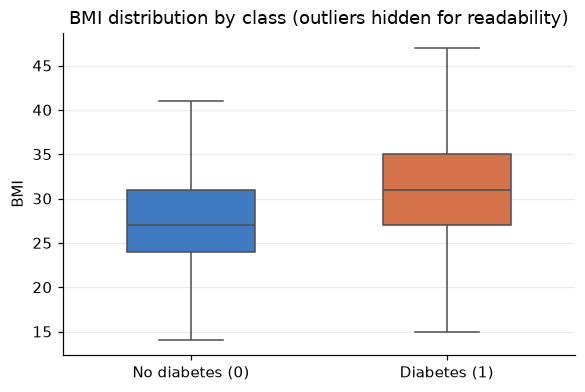

                    count  mean  std   min   25%   50%   75%   max
Diabetes_binary                                                   
0                218334.0  27.8  6.3  12.0  24.0  27.0  31.0  98.0
1                 35346.0  31.9  7.4  13.0  27.0  31.0  35.0  98.0

Rows with BMI > 60: 805 (0.32%)


In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.boxplot(data=df, x=TARGET, y="BMI", hue=TARGET, palette=[COLOR_NO_DIABETES, COLOR_DIABETES],
            showfliers=False, width=0.5, legend=False, ax=ax)
ax.set_xticks([0, 1], labels)
ax.set_xlabel("")
ax.set_title("BMI distribution by class (outliers hidden for readability)")
ax.grid(axis="x", visible=False)
save(fig, "eda_03_bmi_by_class")
plt.show()

print(df.groupby(TARGET)["BMI"].describe().round(1))
print(f"\nRows with BMI > 60: {(df['BMI'] > 60).sum():,} ({(df['BMI'] > 60).mean():.2%})")

## 5. Correlation heatmap (Spearman)
We use **Spearman** rather than Pearson because most features are binary or ordinal (ranked categories). Spearman only assumes order, not equal spacing.

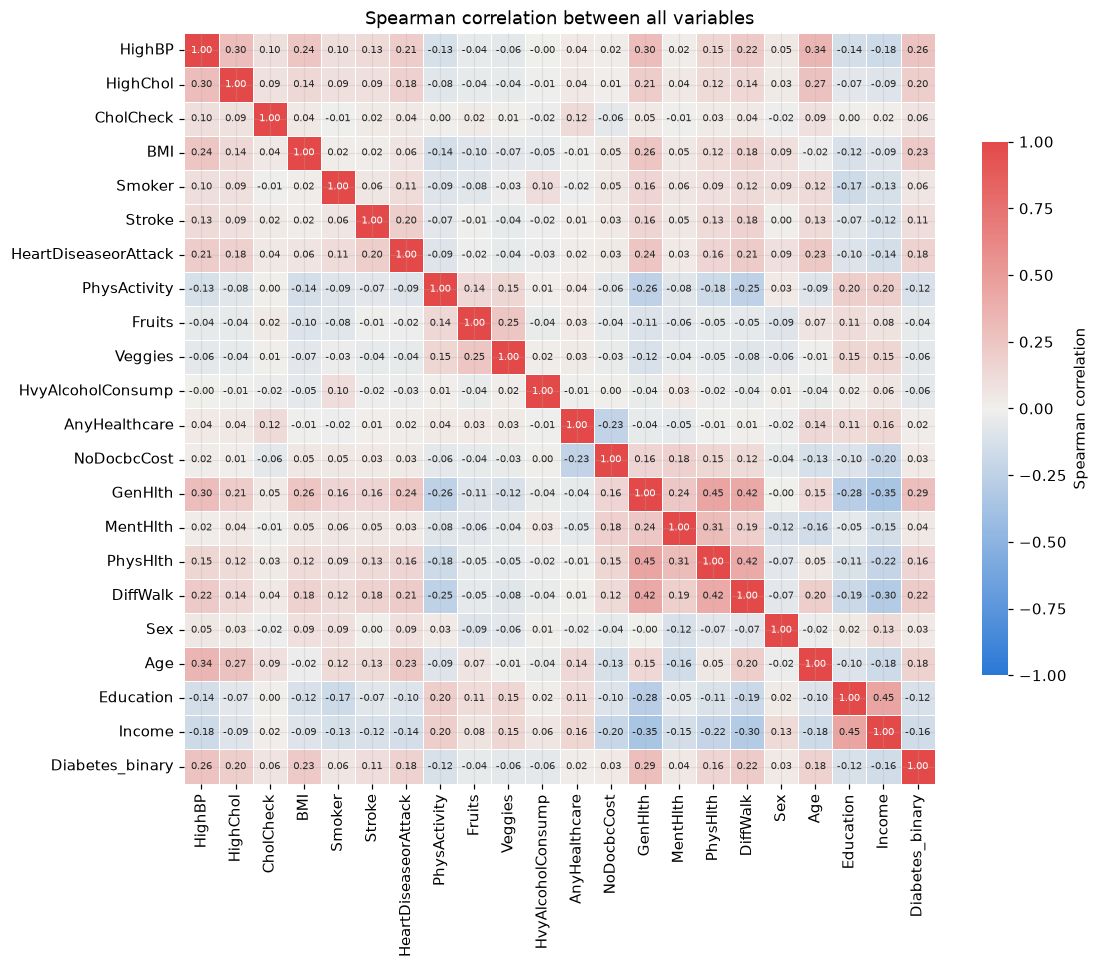

Correlation of each feature with the target (strongest first):
GenHlth                 0.288
HighBP                  0.263
BMI                     0.226
DiffWalk                0.218
HighChol                0.200
Age                     0.178
HeartDiseaseorAttack    0.177
Income                 -0.163
PhysHlth                0.157
Education              -0.120
PhysActivity           -0.118
Stroke                  0.106
CholCheck               0.065
Smoker                  0.061
HvyAlcoholConsump      -0.057
Veggies                -0.057
Fruits                 -0.041
MentHlth                0.040
NoDocbcCost             0.031
Sex                     0.031
AnyHealthcare           0.016
Name: Diabetes_binary, dtype: float64


In [7]:
corr = df.corr(method="spearman")
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=diverging, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6.5}, linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlation between all variables")
save(fig, "eda_04_correlation_heatmap")
plt.show()

print("Correlation of each feature with the target (strongest first):")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

## 6. Diabetes rate by income and education (socio-economic factors, relevant to fairness)

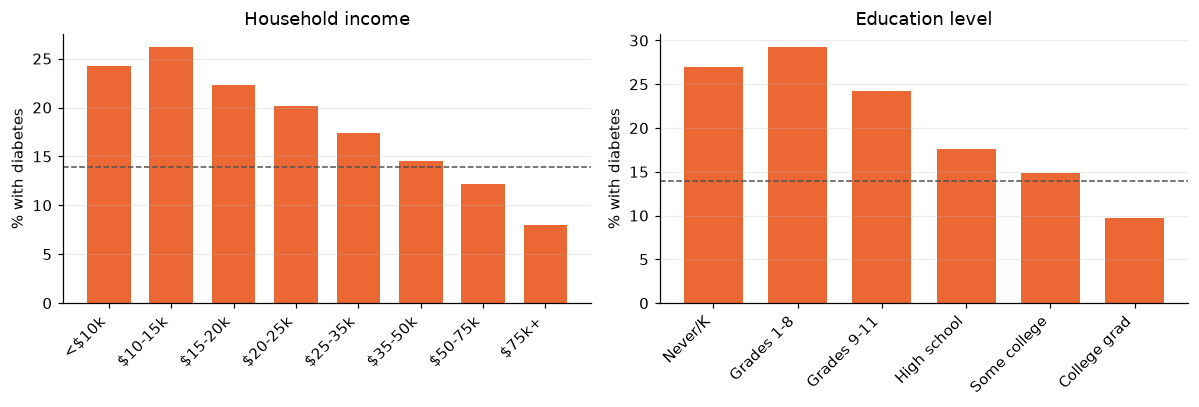

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_rate(axes[0], "Income", ["<$10k", "$10-15k", "$15-20k", "$20-25k", "$25-35k", "$35-50k", "$50-75k", "$75k+"],
          "Household income")
plot_rate(axes[1], "Education", ["Never/K", "Grades 1-8", "Grades 9-11", "High school", "Some college", "College grad"],
          "Education level")
fig.tight_layout()
save(fig, "eda_05_rate_by_income_education")
plt.show()

## 7. EDA findings — fill in after reading the outputs above
Write these in **your own words** for the report. Use only the numbers printed above.

1. **Imbalance:** …% positive → accuracy is misleading; use ROC-AUC, PR-AUC, recall, F1.
2. **Duplicates:** … rows → drop before splitting.
3. **Strongest signals:** (from the correlation list) …
4. **BMI:** median … (no diabetes) vs … (diabetes).
5. **Socio-economic gradient:** diabetes rate falls as income/education rise → fairness check needed in error analysis.
6. **Data quality:** no missing values; ranges valid; BMI has a long right tail (kept, these are real people).